In [19]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (load_data, FEATURE_COLS, NUMERIC_COLS, CATEGORICAL_COLS,
                      FEATURE_GROUPS, CLASS_ORDER, TARGET, RESULTS_DIR)

train, test = load_data()
print("train:", train.shape, "| test:", test.shape)
print(len(FEATURE_COLS), "model inputs =", len(NUMERIC_COLS), "numeric +", len(CATEGORICAL_COLS), "categorical")

train: (175341, 45) | test: (82332, 45)
42 model inputs = 39 numeric + 3 categorical


In [20]:
print(pd.crosstab(train[TARGET], train["label"]))

id_range = train.groupby(TARGET)["id"].agg(["min", "max"]).loc[CLASS_ORDER]
id_range

label               0      1
attack_cat                  
Analysis            0   2000
Backdoor            0   1746
DoS                 0  12264
Exploits            0  33393
Fuzzers             0  18184
Generic             0  40000
Normal          56000      0
Reconnaissance      0  10491
Shellcode           0   1133
Worms               0    130


,min,max
attack_cat,,
Normal,1,115964
Generic,117205,175341
Exploits,48933,175306
Fuzzers,48018,175002
DoS,49000,175249
Reconnaissance,48867,175180
Analysis,47933,172533
Backdoor,47912,174021
Shellcode,48814,175338


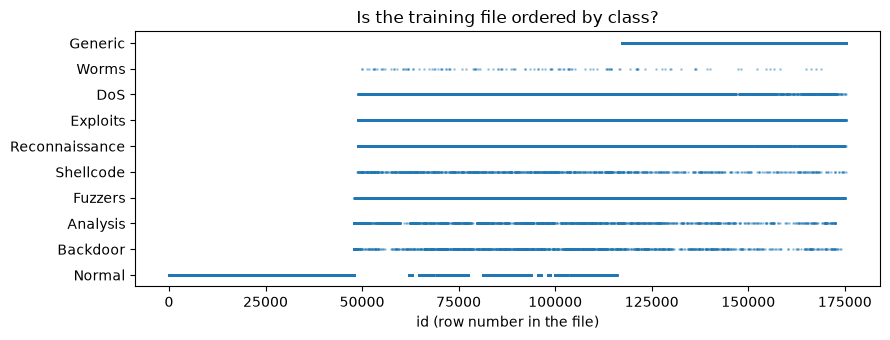

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(train["id"], train[TARGET], s=1, alpha=0.3)
ax.set_xlabel("id (row number in the file)")
ax.set_title("Is the training file ordered by class?")
plt.tight_layout()
plt.show()

                train   test
attack_cat                  
Normal          31.94  44.94
Generic         22.81  22.92
Exploits        19.04  13.52
Fuzzers         10.37   7.36
DoS              6.99   4.97
Reconnaissance   5.98   4.25
Analysis         1.14   0.82
Backdoor         1.00   0.71
Shellcode        0.65   0.46
Worms            0.07   0.05


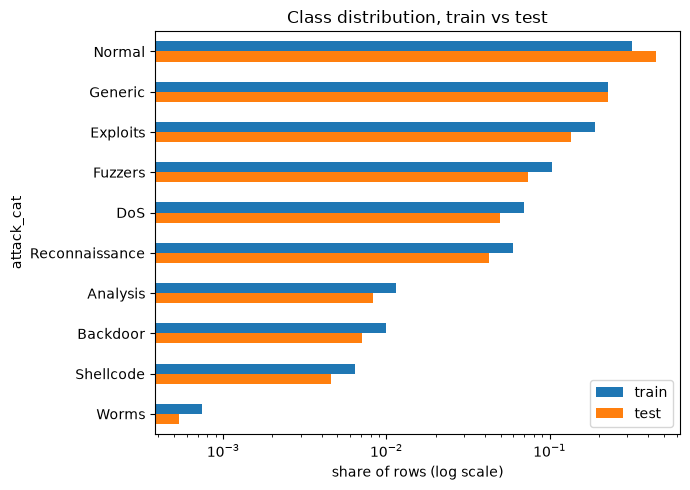

In [22]:
dist = pd.DataFrame({
    "train": train[TARGET].value_counts(normalize=True),
    "test": test[TARGET].value_counts(normalize=True),
}).loc[CLASS_ORDER]
print((dist * 100).round(2))

ax = dist.plot(kind="barh", figsize=(7, 5), logx=True)
ax.invert_yaxis()
ax.set_xlabel("share of rows (log scale)")
ax.set_title("Class distribution, train vs test")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_class_distribution.png", dpi=200)
plt.show()

In [23]:
n_dup = train.duplicated(subset=FEATURE_COLS).sum()
print(f"Rows that exactly repeat an earlier row's features: {n_dup:,} ({n_dup / len(train):.1%})")

Rows that exactly repeat an earlier row's features: 74,301 (42.4%)


In [24]:
n_classes_same_x = train.groupby(FEATURE_COLS)[TARGET].transform("nunique")
contradictory = train[n_classes_same_x > 1]
print(f"Rows whose exact features also appear with another class: "
      f"{len(contradictory):,} ({len(contradictory) / len(train):.1%})")

Rows whose exact features also appear with another class: 30,528 (17.4%)


In [25]:
share = (contradictory[TARGET].value_counts() / train[TARGET].value_counts()).reindex(CLASS_ORDER).fillna(0)
(share * 100).round(1).rename("% of the class in contradictory rows")

attack_cat
Normal             0.7
Generic            0.8
Exploits          39.8
Fuzzers           11.4
DoS               79.5
Reconnaissance    18.0
Analysis          72.0
Backdoor          76.7
Shellcode          0.6
Worms             10.0
Name: % of the class in contradictory rows, dtype: float64

In [26]:
overlap = test[FEATURE_COLS].merge(train[FEATURE_COLS].drop_duplicates(), how="inner")
print(f"Test rows that also appear (same features) in train: {len(overlap):,} ({len(overlap) / len(test):.1%})")

Test rows that also appear (same features) in train: 8,541 (10.4%)


In [27]:
skew = train[NUMERIC_COLS].skew().sort_values(ascending=False)
print(skew.head(10).round(1))
print("\nAny negative value in the numeric features?", (train[NUMERIC_COLS] < 0).any().any())

trans_depth          167.3
response_body_len     76.3
sbytes                45.3
sloss                 44.8
dloss                 41.4
spkts                 40.2
dbytes                39.8
dpkts                 36.8
dinpkt                29.7
djit                  29.5
dtype: float64

Any negative value in the numeric features? False


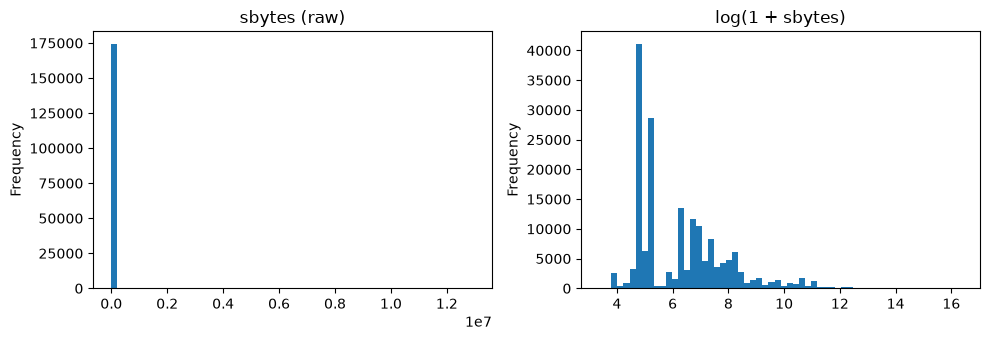

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train["sbytes"].plot(kind="hist", bins=60, ax=axes[0], title="sbytes (raw)")
np.log1p(train["sbytes"]).plot(kind="hist", bins=60, ax=axes[1], title="log(1 + sbytes)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_log_transform.png", dpi=200)
plt.show()

In [29]:
corr = train[NUMERIC_COLS].corr()

# keep each pair only once (the upper triangle of the matrix), then list the strong ones
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack()
strong = pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False)
print(strong.round(3))

is_ftp_login      ct_ftp_cmd          1.000
dbytes            dloss               0.997
sbytes            sloss               0.996
swin              dwin                0.990
ct_srv_src        ct_srv_dst          0.980
dpkts             dloss               0.979
ct_srv_dst        ct_dst_src_ltm      0.972
dpkts             dbytes              0.972
spkts             sloss               0.971
ct_srv_src        ct_dst_src_ltm      0.967
spkts             sbytes              0.964
ct_dst_ltm        ct_src_dport_ltm    0.962
tcprtt            synack              0.949
                  ackdat              0.942
sinpkt            is_sm_ips_ports     0.941
ct_src_dport_ltm  ct_dst_sport_ltm    0.907
dtype: float64


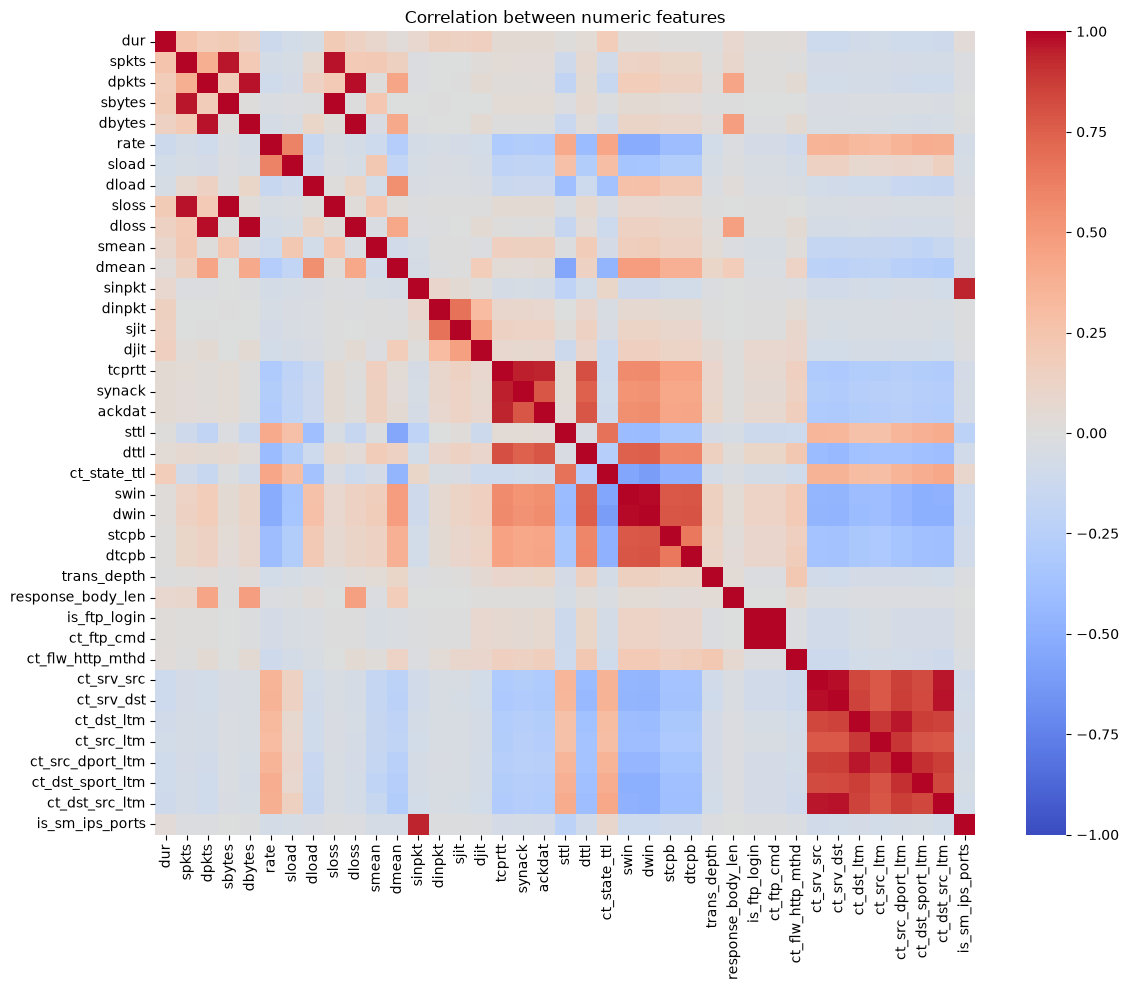

corr(sbytes, smean) = 0.232
sbytes   -0.021
dbytes   -0.136
spkts    -0.103
dpkts    -0.193
Name: sttl, dtype: float64


In [30]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_correlation.png", dpi=200)
plt.show()

print("corr(sbytes, smean) =", round(corr.loc["sbytes", "smean"], 3))
print(corr.loc["sttl", ["sbytes", "dbytes", "spkts", "dpkts"]].round(3))

In [31]:
for col in CATEGORICAL_COLS:
    counts = train[col].value_counts()
    unseen = set(test[col]) - set(train[col])
    print(f"{col:8s} {train[col].nunique():4d} categories | {(counts < 10).sum():3d} appear < 10 times"
          f" | in test but not in train: {unseen or 'none'}")

proto     133 categories |   1 appear < 10 times | in test but not in train: none
service    13 categories |   0 appear < 10 times | in test but not in train: none
state       9 categories |   3 appear < 10 times | in test but not in train: {'ACC', 'CLO'}


In [32]:
(pd.crosstab(train["service"], train[TARGET], normalize="columns")[CLASS_ORDER] * 100).round(1)

attack_cat,Normal,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
service,,,,,,,,,,
dhcp,0.0,0.0,0.2,0.0,0.3,0.0,0.0,0.0,0.0,0.0
dns,13.4,97.8,0.6,2.0,0.9,0.3,0.0,0.0,0.0,0.0
ftp,2.2,0.0,4.8,3.0,0.4,0.0,0.0,0.3,0.0,0.0
ftp-data,4.6,0.0,4.3,0.0,0.1,0.0,0.0,0.0,0.0,0.0
http,9.6,0.7,26.0,4.6,9.9,15.3,27.9,4.8,0.0,87.7
irc,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0
none,65.2,1.3,51.5,90.5,85.4,83.8,71.8,94.3,100.0,12.3
pop3,0.0,0.0,3.1,0.0,0.5,0.0,0.0,0.0,0.0,0.0
radius,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
top_ttl = train["sttl"].value_counts().head(6).index
(pd.crosstab(train["sttl"], train[TARGET], normalize="index").loc[top_ttl, CLASS_ORDER] * 100).round(1)

attack_cat,Normal,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
sttl,,,,,,,,,,
254,9.8,34.7,17.3,15.8,9.5,9.1,1.3,1.5,1.0,0.1
31,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
62,12.3,1.3,75.5,0.3,7.1,0.2,3.1,0.2,0.0,0.0
0,90.4,0.1,5.4,0.5,2.3,0.8,0.1,0.5,0.0,0.0
64,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


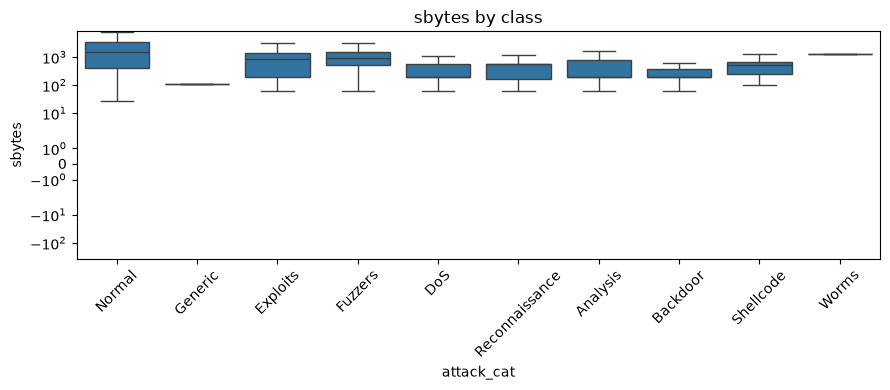

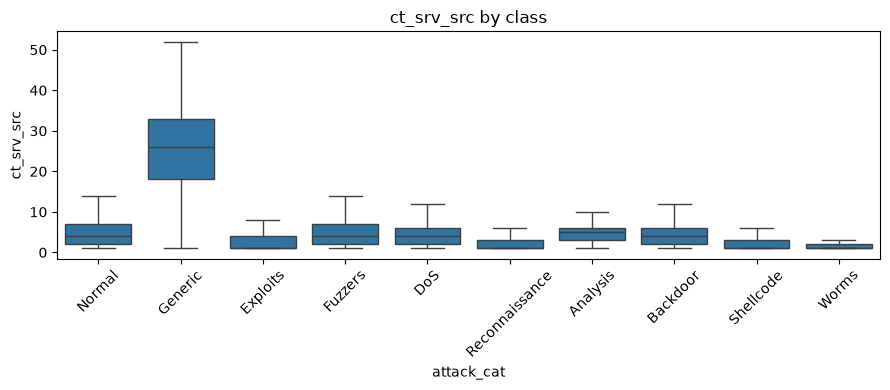

In [34]:
def box_by_class(feature, log=False):
    plt.figure(figsize=(9, 4))
    sns.boxplot(data=train, x=TARGET, y=feature, order=CLASS_ORDER, showfliers=False)
    if log:
        plt.yscale("symlog")
    plt.xticks(rotation=45)
    plt.title(f"{feature} by class")
    plt.tight_layout()
    plt.show()

box_by_class("sbytes", log=True)
box_by_class("ct_srv_src")

In [35]:
rows = [(group, len(cols), ", ".join(cols)) for group, cols in FEATURE_GROUPS.items()]
rows.append(("categorical", len(CATEGORICAL_COLS), ", ".join(CATEGORICAL_COLS)))
feature_table = pd.DataFrame(rows, columns=["group", "n", "features"])
feature_table.to_csv(RESULTS_DIR / "table_feature_groups.csv", index=False)
feature_table

,group,n,features
0,volume,12,"dur, spkts, dpkts, sbytes, dbytes, rate, sload..."
1,timing,7,"sinpkt, dinpkt, sjit, djit, tcprtt, synack, ac..."
2,ttl,3,"sttl, dttl, ct_state_ttl"
3,tcp_header,4,"swin, dwin, stcpb, dtcpb"
4,app_content,5,"trans_depth, response_body_len, is_ftp_login, ..."
5,conn_history,8,"ct_srv_src, ct_srv_dst, ct_dst_ltm, ct_src_ltm..."
6,categorical,3,"proto, service, state"
